Saving sales_data.csv to sales_data.csv
Saving customer_churn.csv to customer_churn.csv
Sales data: (100, 7) | Customer data: (500, 9)
Missing values: sales = 0 | customers = 0

DESCRIPTIVE STATISTICS: SALES DATA (100 orders)
                    Total_Sales  Quantity          Price
Count                    100.00    100.00         100.00
Mean                 123,650.48      4.78      25,808.51
Median                97,955.50      5.00      24,192.00
Mode                       none      4.00           none
Std deviation        100,161.09      2.59      13,917.63
Variance      10,032,243,003.46      6.70 193,700,431.55
Minimum                6,540.00      1.00       1,308.00
Maximum              373,932.00      9.00      49,930.00
Range                367,392.00      8.00      48,622.00
Q1 (25%)              39,517.50      2.75      14,965.25
Q3 (75%)             175,792.50      7.00      38,682.25
IQR                  136,275.00      4.25      23,717.00
Skewness                   0.88  

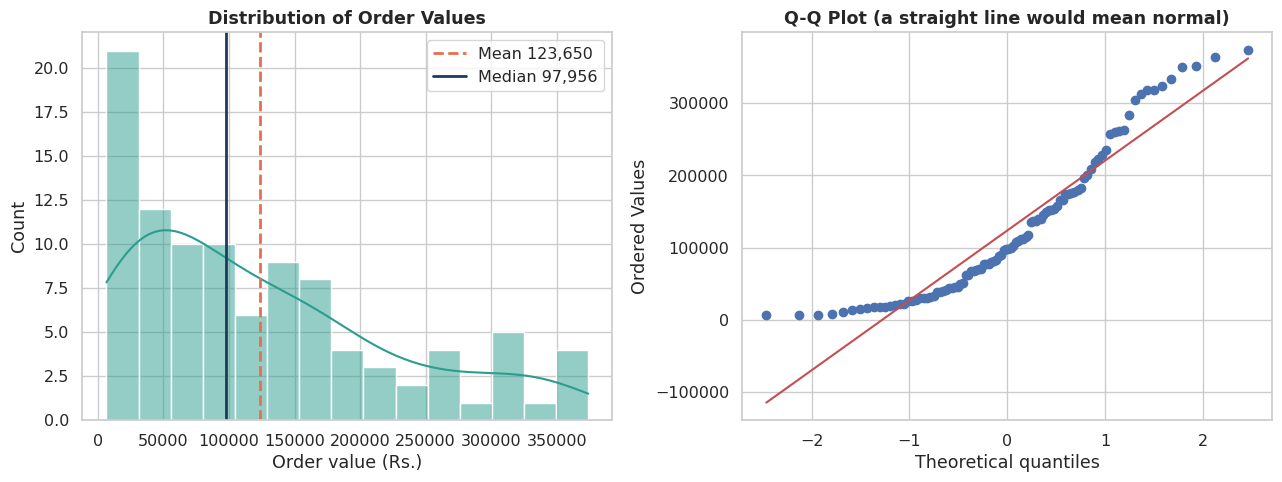

In [ ]:
# Week 7 - Statistical Business Analysis
# Step 1: Load both files, calculate descriptive statistics and check the distribution

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

sns.set_theme(style='whitegrid', font_scale=1.05)
os.makedirs('figures', exist_ok=True)
results_text = []        # every result is saved here and written to a text file at the end

# ---------- Load the two files (any file names work) ----------
uploaded = files.upload()
sales = None
customers = None
for name in uploaded:
    if 'sales' in name.lower():
        sales = pd.read_csv(name)
    elif 'churn' in name.lower() or 'customer' in name.lower():
        customers = pd.read_csv(name)

if sales is None or customers is None:
    print("Error: please upload BOTH files (the sales file and the customer churn file).")
else:
    sales = sales.dropna().drop_duplicates()
    customers = customers.dropna().drop_duplicates()
    sales['Date'] = pd.to_datetime(sales['Date'])
    print("Sales data:", sales.shape, "| Customer data:", customers.shape)
    print("Missing values: sales =", sales.isnull().sum().sum(), "| customers =", customers.isnull().sum().sum())
    print()


    def describe_full(series):
        """All the descriptive statistics for one column."""
        mode = series.mode()
        mode_value = float(mode.iloc[0]) if len(mode) < len(series) else np.nan   # nan = no repeated value
        return {'Count': float(len(series)), 'Mean': series.mean(), 'Median': series.median(),
                'Mode': mode_value, 'Std deviation': series.std(), 'Variance': series.var(),
                'Minimum': series.min(), 'Maximum': series.max(), 'Range': series.max() - series.min(),
                'Q1 (25%)': series.quantile(0.25), 'Q3 (75%)': series.quantile(0.75),
                'IQR': series.quantile(0.75) - series.quantile(0.25),
                'Skewness': series.skew(), 'Kurtosis': series.kurt()}


    # ---------- Descriptive statistics: sales data ----------
    print("=" * 55)
    print("DESCRIPTIVE STATISTICS: SALES DATA (100 orders)")
    print("=" * 55)
    table = pd.DataFrame({col: describe_full(sales[col]) for col in ['Total_Sales', 'Quantity', 'Price']})
    print(table.to_string(float_format=lambda v: f"{v:,.2f}", na_rep='none'))
    print("(Mode 'none' means no value repeats, so every value is different.)")
    results_text.append("DESCRIPTIVE STATISTICS: SALES DATA\n" + table.to_string(float_format=lambda v: f"{v:,.2f}", na_rep='none'))

    print()
    print("Total_Sales by product (mean, median, standard deviation):")
    by_product = sales.groupby('Product')['Total_Sales'].agg(['count', 'mean', 'median', 'std']).round(0)
    print(by_product)
    print()
    print("Most common product:", sales['Product'].mode()[0], "| Most common region:", sales['Region'].mode()[0])

    # ---------- Descriptive statistics: customer data ----------
    print()
    print("=" * 55)
    print("DESCRIPTIVE STATISTICS: CUSTOMER DATA (500 customers)")
    print("=" * 55)
    table2 = pd.DataFrame({col: describe_full(customers[col]) for col in ['Tenure', 'MonthlyCharges', 'TotalCharges']})
    print(table2.to_string(float_format=lambda v: f"{v:,.2f}", na_rep='none'))
    results_text.append("DESCRIPTIVE STATISTICS: CUSTOMER DATA\n" + table2.to_string(float_format=lambda v: f"{v:,.2f}", na_rep='none'))
    print()
    print(f"Churn rate: {customers['Churn'].mean() * 100:.1f}% ({customers['Churn'].sum()} of {len(customers)} customers left)")

    # ---------- Distribution of order values ----------
    print()
    print("=" * 55)
    print("DISTRIBUTION OF ORDER VALUES")
    print("=" * 55)
    x = sales['Total_Sales']
    stat, p = stats.shapiro(x)
    print(f"Shapiro-Wilk normality test: statistic = {stat:.3f}, p-value = {p:.2e}")
    if p < 0.05:
        print("Result: p < 0.05, so the order values are NOT normally distributed.")
        print(f"They are skewed to the right (skewness = {x.skew():.2f}): the mean ({x.mean():,.0f}) is higher than the median ({x.median():,.0f}).")
    else:
        print("Result: p >= 0.05, so the order values look normally distributed.")
    results_text.append(f"NORMALITY TEST (Shapiro-Wilk) on Total_Sales: statistic = {stat:.3f}, p = {p:.2e}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.histplot(x, bins=15, kde=True, color='#2a9d8f', ax=axes[0])
    axes[0].axvline(x.mean(), color='#e76f51', linestyle='--', linewidth=2, label=f"Mean {x.mean():,.0f}")
    axes[0].axvline(x.median(), color='#1f3a5f', linestyle='-', linewidth=2, label=f"Median {x.median():,.0f}")
    axes[0].set_title('Distribution of Order Values', fontweight='bold')
    axes[0].set_xlabel('Order value (Rs.)')
    axes[0].legend()
    stats.probplot(x, dist='norm', plot=axes[1])
    axes[1].set_title('Q-Q Plot (a straight line would mean normal)', fontweight='bold')
    plt.tight_layout()
    plt.savefig('figures/1_distribution_order_values.png', dpi=150, bbox_inches='tight')
    plt.show()

CORRELATION ANALYSIS
There is no marketing-spend column in this data, so we study the
relationships that the data does contain.

Pearson correlation matrix (sales data):
             Quantity  Price  Total_Sales
Quantity        1.000  0.008        0.688
Price           0.008  1.000        0.646
Total_Sales     0.688  0.646        1.000

Covariance matrix (sales data):
             Quantity        Price   Total_Sales
Quantity          7.0        289.0  1.783800e+05
Price           289.0  193700432.0  9.007097e+08
Total_Sales  178380.0  900709746.0  1.003224e+10

  Quantity vs Total_Sales: Pearson r = 0.688 (p = 2.6e-15), Spearman rho = 0.691 (p = 1.7e-15)
  Price vs Total_Sales: Pearson r = 0.646 (p = 3.9e-13), Spearman rho = 0.680 (p = 7.4e-15)
  Quantity vs Price: Pearson r = 0.008 (p = 0.94)

How to read r: 0 = no link, 0.3 = weak, 0.5 = moderate, 0.7+ = strong.
Order value is strongly linked with both quantity and price.
Quantity and price are not linked with each other.

Pearson co

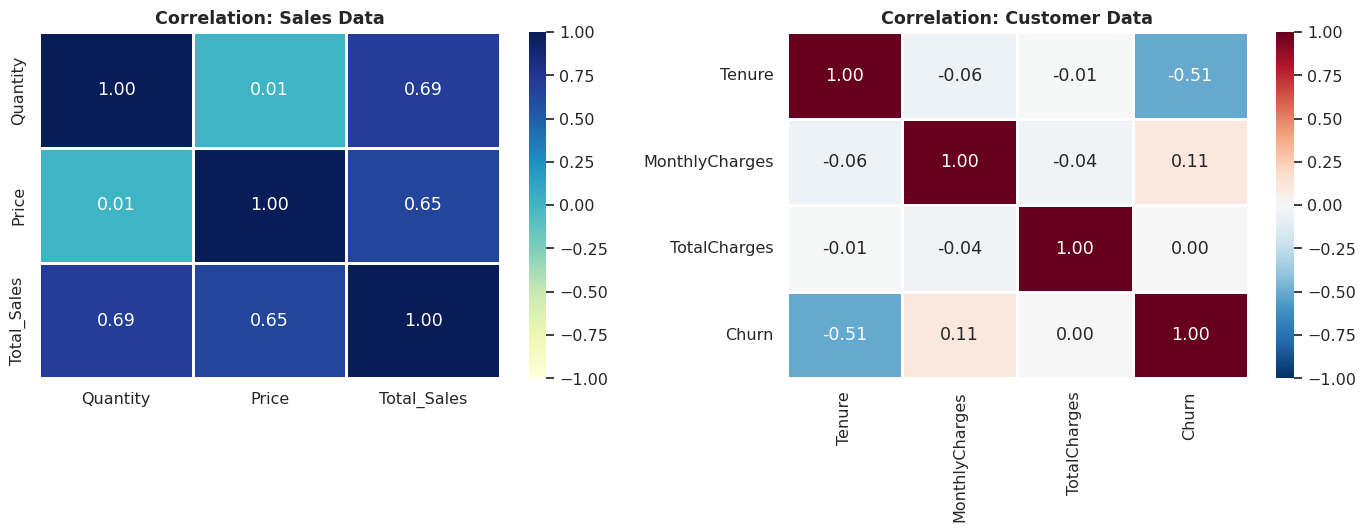

HYPOTHESIS TESTS (significance level alpha = 0.05)
A p-value below 0.05 means the difference is unlikely to be just chance.

TEST 1: Are West orders smaller than orders in the other regions? (Welch t-test)
  H0 (no effect):  mean order value is the same in West and the other regions
  H1 (effect):     mean order value is different
  Result:          West mean = 81,689, others mean = 138,394, t = -2.72, Cohen's d = -0.58, p-value = 0.008887
  Decision (alpha = 0.05): REJECT H0 (significant)
  Meaning:         West orders are about Rs.56,704 smaller on average. The non-parametric Mann-Whitney test agrees (p = 0.003335). West was chosen after seeing the data, so treat this as exploratory; even with a Bonferroni correction for the 4 regions (p x 4 = 0.036) it stays significant.

TEST 2: Are Laptop orders bigger than orders for other products? (Welch t-test)
  H0 (no effect):  mean order value is the same for Laptop and other products
  H1 (effect):     mean order value is different
  Resul

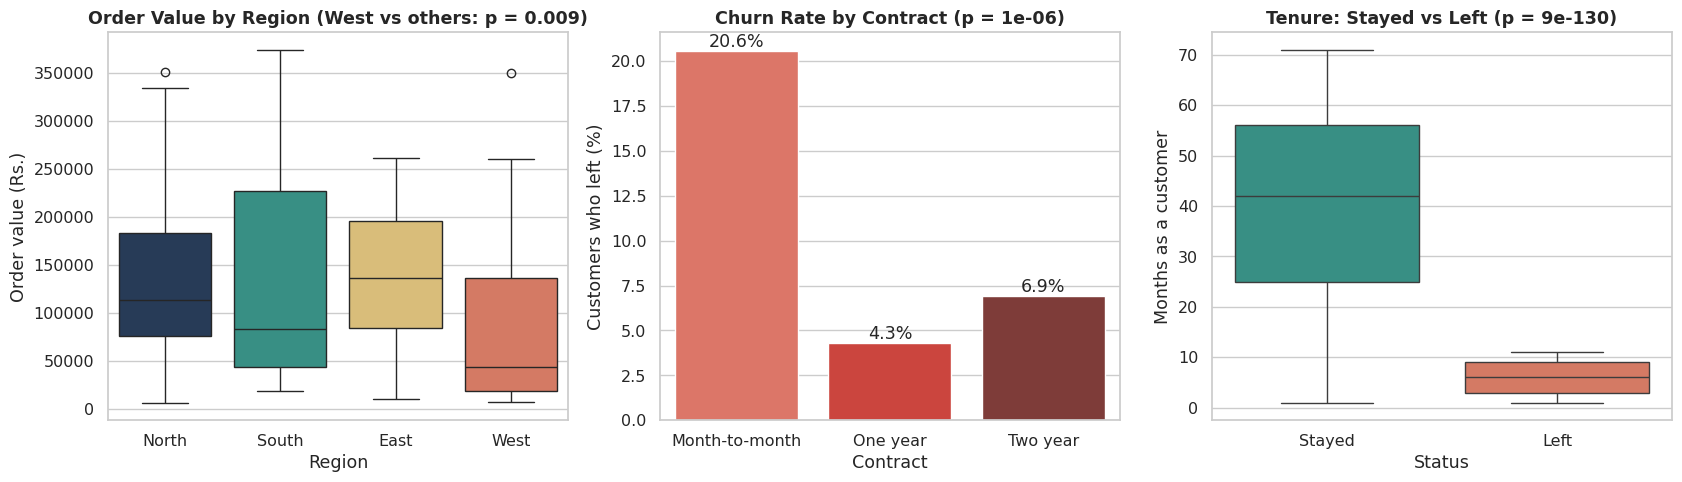

In [ ]:
# Step 2: Correlation analysis and hypothesis tests

ALPHA = 0.05          # significance level: p < 0.05 means "statistically significant"


def report_test(number, name, h0, h1, test_text, p, meaning):
    """Print one hypothesis test in a clear format and save it for the results file."""
    decision = "REJECT H0 (significant)" if p < ALPHA else "FAIL TO REJECT H0 (not significant)"
    block = (f"TEST {number}: {name}\n"
             f"  H0 (no effect):  {h0}\n"
             f"  H1 (effect):     {h1}\n"
             f"  Result:          {test_text}, p-value = {p:.4g}\n"
             f"  Decision (alpha = {ALPHA}): {decision}\n"
             f"  Meaning:         {meaning}\n")
    print(block)
    results_text.append(block)


def cohens_d(a, b):
    """Effect size: how big is the difference, in standard deviations."""
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled


# =====================================================================
# PART A: CORRELATION AND COVARIANCE
# =====================================================================
print("=" * 60)
print("CORRELATION ANALYSIS")
print("=" * 60)
print("There is no marketing-spend column in this data, so we study the")
print("relationships that the data does contain.\n")

num_cols = ['Quantity', 'Price', 'Total_Sales']
corr_sales = sales[num_cols].corr(method='pearson')
print("Pearson correlation matrix (sales data):")
print(corr_sales.round(3))
print()
print("Covariance matrix (sales data):")
print(sales[num_cols].cov().round(0))
print()
corr_lines = ["CORRELATION ANALYSIS (Pearson and Spearman, sales data)"]
for col in ['Quantity', 'Price']:
    r, p_r = stats.pearsonr(sales[col], sales['Total_Sales'])
    rho, p_rho = stats.spearmanr(sales[col], sales['Total_Sales'])
    line = f"  {col} vs Total_Sales: Pearson r = {r:.3f} (p = {p_r:.2g}), Spearman rho = {rho:.3f} (p = {p_rho:.2g})"
    print(line)
    corr_lines.append(line)
r_qp, p_qp = stats.pearsonr(sales['Quantity'], sales['Price'])
line = f"  Quantity vs Price: Pearson r = {r_qp:.3f} (p = {p_qp:.2g})"
print(line)
corr_lines.append(line)
results_text.append("\n".join(corr_lines))
print()
print("How to read r: 0 = no link, 0.3 = weak, 0.5 = moderate, 0.7+ = strong.")
print("Order value is strongly linked with both quantity and price.")
print("Quantity and price are not linked with each other.")

cust_cols = ['Tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_cust = customers[cust_cols].corr()
print()
print("Pearson correlation matrix (customer data):")
print(corr_cust.round(3))
r_t, p_t = stats.pearsonr(customers['Tenure'], customers['Churn'])
print(f"\nTenure vs Churn: r = {r_t:.3f} (p = {p_t:.2g}): longer-staying customers are much less likely to leave.")
results_text.append("CORRELATION (customer data)\n" + corr_cust.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(corr_sales, annot=True, fmt='.2f', cmap='YlGnBu', vmin=-1, vmax=1,
            linewidths=1, linecolor='white', ax=axes[0])
axes[0].set_title('Correlation: Sales Data', fontweight='bold')
sns.heatmap(corr_cust, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor='white', ax=axes[1])
axes[1].set_title('Correlation: Customer Data', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/2_correlation_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

# =====================================================================
# PART B: HYPOTHESIS TESTS
# =====================================================================
print("=" * 60)
print("HYPOTHESIS TESTS (significance level alpha = 0.05)")
print("=" * 60)
print("A p-value below 0.05 means the difference is unlikely to be just chance.\n")
results_text.append("HYPOTHESIS TESTS (alpha = 0.05)")

# ---- Test 1: West region against the other regions (Welch t-test) ----
west = sales.loc[sales['Region'] == 'West', 'Total_Sales']
others = sales.loc[sales['Region'] != 'West', 'Total_Sales']
t, p1 = stats.ttest_ind(west, others, equal_var=False)
u, p1_mw = stats.mannwhitneyu(west, others)
d = cohens_d(west, others)
report_test(1, "Are West orders smaller than orders in the other regions? (Welch t-test)",
            "mean order value is the same in West and the other regions",
            "mean order value is different",
            f"West mean = {west.mean():,.0f}, others mean = {others.mean():,.0f}, t = {t:.2f}, Cohen's d = {d:.2f}", p1,
            f"West orders are about Rs.{others.mean() - west.mean():,.0f} smaller on average. "
            f"The non-parametric Mann-Whitney test agrees (p = {p1_mw:.4g}). "
            f"West was chosen after seeing the data, so treat this as exploratory; "
            f"even with a Bonferroni correction for the 4 regions (p x 4 = {min(p1 * 4, 1):.3f}) it stays {'significant' if p1 * 4 < ALPHA else 'not significant'}.")

# ---- Test 2: Laptop against all other products (Welch t-test) ----
lap = sales.loc[sales['Product'] == 'Laptop', 'Total_Sales']
nolap = sales.loc[sales['Product'] != 'Laptop', 'Total_Sales']
t, p2 = stats.ttest_ind(lap, nolap, equal_var=False)
d = cohens_d(lap, nolap)
report_test(2, "Are Laptop orders bigger than orders for other products? (Welch t-test)",
            "mean order value is the same for Laptop and other products",
            "mean order value is different",
            f"Laptop mean = {lap.mean():,.0f}, others mean = {nolap.mean():,.0f}, t = {t:.2f}, Cohen's d = {d:.2f}", p2,
            "Laptop orders look bigger, but with only 24 laptop orders the data cannot rule out chance at the 5% level.")

# ---- Test 3: Order value across the 5 products (one-way ANOVA) ----
groups = [g['Total_Sales'].values for _, g in sales.groupby('Product')]
F, p3 = stats.f_oneway(*groups)
H, p3_kw = stats.kruskal(*groups)
report_test(3, "Does the mean order value differ between the 5 products? (one-way ANOVA)",
            "all 5 products have the same mean order value",
            "at least one product has a different mean",
            f"F = {F:.2f}", p3,
            f"No clear evidence of a difference between products. The Kruskal-Wallis test agrees (p = {p3_kw:.4g}).")

# ---- Test 4: Order value across the 4 regions (one-way ANOVA) ----
groups = [g['Total_Sales'].values for _, g in sales.groupby('Region')]
F, p4 = stats.f_oneway(*groups)
report_test(4, "Does the mean order value differ between the 4 regions? (one-way ANOVA)",
            "all 4 regions have the same mean order value",
            "at least one region has a different mean",
            f"F = {F:.2f}", p4,
            "Overall, the 4 regions are not clearly different at the 5% level, even though West on its own looked smaller in Test 1.")

# ---- Test 5: Churn and contract type (chi-square test of independence) ----
table_ct = pd.crosstab(customers['Contract'], customers['Churn'])
chi2, p5, dof, _ = stats.chi2_contingency(table_ct)
rates = (table_ct[1] / table_ct.sum(axis=1) * 100).round(1)
report_test(5, "Is leaving (churn) linked with the contract type? (chi-square test)",
            "churn is independent of the contract type",
            "churn depends on the contract type",
            f"chi-square = {chi2:.2f}, degrees of freedom = {dof}", p5,
            f"Churn rates: month-to-month {rates['Month-to-month']}%, one year {rates['One year']}%, two year {rates['Two year']}%. "
            "Month-to-month customers leave much more often.")

# ---- Test 6: Tenure of customers who left and who stayed (Welch t-test) ----
left = customers[customers['Churn'] == 1]
stayed = customers[customers['Churn'] == 0]
t, p6 = stats.ttest_ind(left['Tenure'], stayed['Tenure'], equal_var=False)
d = cohens_d(left['Tenure'], stayed['Tenure'])
report_test(6, "Do customers who left have a different tenure? (Welch t-test)",
            "mean tenure is the same for customers who left and who stayed",
            "mean tenure is different",
            f"left mean = {left['Tenure'].mean():.1f} months, stayed mean = {stayed['Tenure'].mean():.1f} months, t = {t:.2f}, Cohen's d = {d:.2f}", p6,
            "Customers who left had only a few months of tenure. The difference is huge and not due to chance.")

# ---- Test 7: Monthly charges of customers who left and who stayed (Welch t-test) ----
t, p7 = stats.ttest_ind(left['MonthlyCharges'], stayed['MonthlyCharges'], equal_var=False)
d = cohens_d(left['MonthlyCharges'], stayed['MonthlyCharges'])
report_test(7, "Do customers who left pay different monthly charges? (Welch t-test)",
            "mean monthly charge is the same for customers who left and who stayed",
            "mean monthly charge is different",
            f"left mean = {left['MonthlyCharges'].mean():.1f}, stayed mean = {stayed['MonthlyCharges'].mean():.1f}, t = {t:.2f}, Cohen's d = {d:.2f}", p7,
            "Customers who left paid more per month on average, a small to moderate difference.")

# ---- Tests 8 to 10: other customer features against churn (chi-square tests) ----
for number, col in zip([8, 9, 10], ['PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']):
    tab = pd.crosstab(customers[col], customers['Churn'])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    report_test(number, f"Is churn linked with {col}? (chi-square test)",
                f"churn is independent of {col}", f"churn depends on {col}",
                f"chi-square = {chi2:.2f}, degrees of freedom = {dof}", p,
                "No evidence of a link." if p >= ALPHA else "There is a link.")

# ---------- A picture of the main tests ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
order_r = ['North', 'South', 'East', 'West']
sns.boxplot(data=sales, x='Region', y='Total_Sales', hue='Region', order=order_r,
            palette={'North': '#1f3a5f', 'South': '#2a9d8f', 'East': '#e9c46a', 'West': '#e76f51'},
            legend=False, ax=axes[0])
axes[0].set_title(f'Order Value by Region (West vs others: p = {p1:.3f})', fontweight='bold')
axes[0].set_ylabel('Order value (Rs.)')
rate_df = (customers.groupby('Contract')['Churn'].mean() * 100).reset_index()
sns.barplot(data=rate_df, x='Contract', y='Churn', hue='Contract', palette='Reds_d', legend=False, ax=axes[1])
axes[1].set_title(f'Churn Rate by Contract (p = {p5:.1g})', fontweight='bold')
axes[1].set_ylabel('Customers who left (%)')
for bar in axes[1].patches:
    axes[1].annotate(f"{bar.get_height():.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha='center', va='bottom')
customers['Status'] = customers['Churn'].map({0: 'Stayed', 1: 'Left'})
sns.boxplot(data=customers, x='Status', y='Tenure', hue='Status', order=['Stayed', 'Left'],
            palette={'Stayed': '#2a9d8f', 'Left': '#e76f51'}, legend=False, ax=axes[2])
axes[2].set_title(f'Tenure: Stayed vs Left (p = {p6:.1g})', fontweight='bold')
axes[2].set_ylabel('Months as a customer')
plt.tight_layout()
plt.savefig('figures/3_hypothesis_tests.png', dpi=150, bbox_inches='tight')
plt.show()

95% CONFIDENCE INTERVALS
A confidence interval is a range that very likely contains the true value.
The margin of error is half the width of that range.

CI 1: Average order value = Rs.123,650, 95% CI = Rs.103,776 to Rs.143,525 (margin of error = Rs.19,874, 16.1% of the mean)
  Meaning: we are 95% confident that the true average order value is in this range.

CI 2: Average order value by product
            Orders      Mean    CI low   CI high  Margin of error
Product                                                          
Laptop          24  162050.0  112827.0  211274.0          49223.0
Phone           20  142970.0   92803.0  193137.0          50167.0
Tablet          26  110936.0   77668.0  144205.0          33269.0
Headphones      15   92269.0   39008.0  145530.0          53261.0
Monitor         15   89871.0   46901.0  132842.0          42971.0
  Meaning: the ranges overlap a lot, which agrees with the ANOVA result (no clear difference between products).

CI 3: West minus other reg

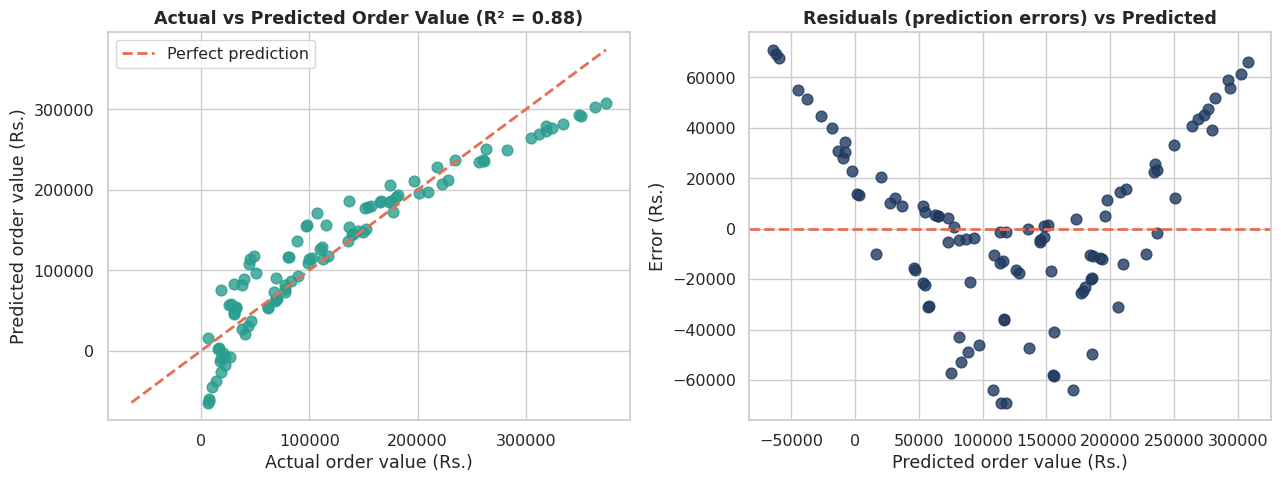

In [ ]:
# Step 3: Confidence intervals and regression analysis

import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint

# =====================================================================
# PART A: 95% CONFIDENCE INTERVALS
# =====================================================================
print("=" * 60)
print("95% CONFIDENCE INTERVALS")
print("=" * 60)
print("A confidence interval is a range that very likely contains the true value.")
print("The margin of error is half the width of that range.\n")
results_text.append("95% CONFIDENCE INTERVALS")


def mean_ci(series, confidence=0.95):
    """Confidence interval for a mean (t-distribution)."""
    n = len(series)
    se = stats.sem(series)
    margin = stats.t.ppf((1 + confidence) / 2, n - 1) * se
    return series.mean(), series.mean() - margin, series.mean() + margin, margin


# ---- CI 1: average order value ----
m, low, high, margin = mean_ci(sales['Total_Sales'])
text = (f"CI 1: Average order value = Rs.{m:,.0f}, 95% CI = Rs.{low:,.0f} to Rs.{high:,.0f} "
        f"(margin of error = Rs.{margin:,.0f}, {margin / m * 100:.1f}% of the mean)")
print(text)
print("  Meaning: we are 95% confident that the true average order value is in this range.\n")
results_text.append(text)

# ---- CI 2: average order value for each product ----
rows = []
for product, g in sales.groupby('Product'):
    m, low, high, margin = mean_ci(g['Total_Sales'])
    rows.append({'Product': product, 'Orders': len(g), 'Mean': m, 'CI low': low, 'CI high': high, 'Margin of error': margin})
ci_products = pd.DataFrame(rows).set_index('Product').sort_values('Mean', ascending=False)
print("CI 2: Average order value by product")
print(ci_products.round(0).to_string())
print("  Meaning: the ranges overlap a lot, which agrees with the ANOVA result (no clear difference between products).\n")
results_text.append("CI 2: Average order value by product\n" + ci_products.round(0).to_string())

# ---- CI 3: difference between West and the other regions ----
n1, n2 = len(west), len(others)
v1, v2 = west.var() / n1, others.var() / n2
diff = west.mean() - others.mean()
se = np.sqrt(v1 + v2)
df_welch = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))
margin = stats.t.ppf(0.975, df_welch) * se
text = (f"CI 3: West minus other regions = Rs.{diff:,.0f}, 95% CI = Rs.{diff - margin:,.0f} to Rs.{diff + margin:,.0f}")
print(text)
print("  Meaning: the whole range is below zero, so West orders are smaller (this agrees with Test 1).\n"
      if diff + margin < 0 else "  Meaning: the range includes zero, so the difference may be chance.\n")
results_text.append(text)

# ---- CI 4: churn rate (proportion, Wilson method) ----
n_left, n_all = int(customers['Churn'].sum()), len(customers)
low, high = proportion_confint(n_left, n_all, alpha=0.05, method='wilson')
text = f"CI 4: Overall churn rate = {n_left / n_all * 100:.1f}% ({n_left} of {n_all}), 95% CI = {low * 100:.1f}% to {high * 100:.1f}%"
print(text)
results_text.append(text)
print("CI 5: Churn rate by contract type")
rows = []
for contract, g in customers.groupby('Contract'):
    k, n = int(g['Churn'].sum()), len(g)
    low, high = proportion_confint(k, n, alpha=0.05, method='wilson')
    rows.append({'Contract': contract, 'Customers': n, 'Left': k,
                 'Churn %': k / n * 100, 'CI low %': low * 100, 'CI high %': high * 100})
ci_churn = pd.DataFrame(rows).set_index('Contract')
print(ci_churn.round(1).to_string())
print("  Meaning: the month-to-month range does not overlap with the one-year range, so month-to-month churn is really higher.\n")
results_text.append("CI 5: Churn rate by contract type\n" + ci_churn.round(1).to_string())

# =====================================================================
# PART B: REGRESSION ANALYSIS
# =====================================================================
print("=" * 60)
print("REGRESSION ANALYSIS")
print("=" * 60)
print("Model 1: Total_Sales = intercept + b1 x Quantity + b2 x Price\n")
X = sm.add_constant(sales[['Quantity', 'Price']])
y = sales['Total_Sales']
model = sm.OLS(y, X).fit()
coef = pd.DataFrame({'Coefficient': model.params, 'CI low': model.conf_int()[0],
                     'CI high': model.conf_int()[1], 'p-value': model.pvalues})
print(coef.to_string(formatters={'p-value': lambda v: f"{v:.2e}"}, float_format=lambda v: f"{v:,.2f}"))
print()
print(f"R-squared = {model.rsquared:.3f}   Adjusted R-squared = {model.rsquared_adj:.3f}")
print(f"F-test: F = {model.fvalue:.1f}, p-value = {model.f_pvalue:.2e}   (n = {int(model.nobs)} orders)")
print()
print(f"Meaning: Quantity and Price together explain {model.rsquared * 100:.1f}% of the differences in order value.")
print(f"  Each extra unit adds about Rs.{model.params['Quantity']:,.0f} to an order (price held the same).")
print(f"  Each extra Rs.1 of price adds about Rs.{model.params['Price']:.2f} to an order (quantity held the same).")
results_text.append("REGRESSION MODEL 1: Total_Sales ~ Quantity + Price\n" +
                    coef.to_string(formatters={'p-value': lambda v: f"{v:.2e}"}, float_format=lambda v: f"{v:,.2f}") +
                    f"\nR-squared = {model.rsquared:.3f}, adjusted R-squared = {model.rsquared_adj:.3f}, "
                    f"F = {model.fvalue:.1f}, p = {model.f_pvalue:.2e}, n = {int(model.nobs)}")

# A check that explains why R-squared is not 1.0
exact = np.allclose(sales['Total_Sales'], sales['Quantity'] * sales['Price'])
print()
print(f"Check: is Total_Sales exactly Quantity x Price in every row? {exact}")
print("A straight-line model cannot copy a multiplication, so Model 1 is good but not perfect.")
print("Model 2 uses logarithms, which turn a multiplication into an addition:\n")
X2 = sm.add_constant(np.log(sales[['Quantity', 'Price']]))
model2 = sm.OLS(np.log(sales['Total_Sales']), X2).fit()
print(model2.params.round(4).to_string())
print(f"R-squared = {model2.rsquared:.3f}")
print("Both coefficients are 1 and R-squared is 1: order value is built from quantity x price, so this regression")
print("confirms how the data was recorded. It is a demonstration of the method, not a surprising discovery.")
results_text.append(f"REGRESSION MODEL 2 (log-log): log(Total_Sales) ~ log(Quantity) + log(Price)\n"
                    f"{model2.params.round(4).to_string()}\nR-squared = {model2.rsquared:.3f}\n"
                    f"Total_Sales equals Quantity x Price in every row: {exact}")

# ---------- Regression pictures ----------
fitted = model.fittedvalues
resid = model.resid
print()
print(f"Residual check: the smallest predicted order value is Rs.{fitted.min():,.0f}.")
print("A negative order value is impossible, and the errors form a U-shaped curve in the right-hand picture.")
print("This shows that the straight-line Model 1 is only an approximation; Model 2 (logarithms) fits the data exactly.")
results_text.append(f"Residual check: smallest predicted order value = Rs.{fitted.min():,.0f}; the residuals form a U-shaped curve, "
                    "so the straight-line model is only an approximation (Model 2 fits exactly).")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y, fitted, color='#2a9d8f', alpha=0.8, s=60)
lims = [min(y.min(), fitted.min()), max(y.max(), fitted.max())]
axes[0].plot(lims, lims, color='#e76f51', linestyle='--', linewidth=2, label='Perfect prediction')
axes[0].set_title(f'Actual vs Predicted Order Value (R² = {model.rsquared:.2f})', fontweight='bold')
axes[0].set_xlabel('Actual order value (Rs.)')
axes[0].set_ylabel('Predicted order value (Rs.)')
axes[0].legend()
axes[1].scatter(fitted, resid, color='#1f3a5f', alpha=0.8, s=60)
axes[1].axhline(0, color='#e76f51', linestyle='--', linewidth=2)
axes[1].set_title('Residuals (prediction errors) vs Predicted', fontweight='bold')
axes[1].set_xlabel('Predicted order value (Rs.)')
axes[1].set_ylabel('Error (Rs.)')
plt.tight_layout()
plt.savefig('figures/4_regression.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Step 4: Save all results in a text file and download it

# With 10 hypothesis tests, a few "significant" results can appear just by chance.
# A Bonferroni correction multiplies each p-value by the number of tests (10) to be stricter.
N_TESTS = 10
tests_checked = {
    "Test 1: West vs other regions (order value)": p1,
    "Test 2: Laptop vs other products (order value)": p2,
    "Test 3: ANOVA across products": p3,
    "Test 4: ANOVA across regions": p4,
    "Test 5: Churn vs contract type": p5,
    "Test 6: Tenure of customers who left vs stayed": p6,
    "Test 7: Monthly charges of customers who left vs stayed": p7,
}
correction_lines = ["BONFERRONI CHECK (10 tests were run, so each p-value is multiplied by 10)"]
for name, p in tests_checked.items():
    adjusted = min(p * N_TESTS, 1)
    verdict = "still significant" if adjusted < ALPHA else "NOT significant after the correction"
    correction_lines.append(f"  {name}: p = {p:.3g}, adjusted p = {adjusted:.3g} -> {verdict}")
correction_lines.append("  The strongest results (churn vs contract type, and tenure) survive the correction. "
                        "The West and monthly-charges results are weaker evidence and should be confirmed with more data.")
print("\n".join(correction_lines))
results_text.append("\n".join(correction_lines))

header = ["HYPOTHESIS TESTS AND STATISTICAL RESULTS",
          "Statistical Business Analysis (Week 7)",
          "Data: sales_data.csv (100 orders) and customer_churn.csv (500 customers)",
          "Significance level: alpha = 0.05",
          "Note: the data has no marketing-spend column, so marketing spend was not analysed."]
separator = "\n\n" + "-" * 70 + "\n\n"
with open('hypothesis_tests_results.txt', 'w', encoding='utf-8') as f:
    f.write("\n".join(header) + "\n\n" + "=" * 70 + "\n\n")
    f.write(separator.join(results_text) + "\n")

print()
print("Saved hypothesis_tests_results.txt with", len(results_text), "result sections.")
files.download('hypothesis_tests_results.txt')

BONFERRONI CHECK (10 tests were run, so each p-value is multiplied by 10)
  Test 1: West vs other regions (order value): p = 0.00889, adjusted p = 0.0889 -> NOT significant after the correction
  Test 2: Laptop vs other products (order value): p = 0.0609, adjusted p = 0.609 -> NOT significant after the correction
  Test 3: ANOVA across products: p = 0.0934, adjusted p = 0.934 -> NOT significant after the correction
  Test 4: ANOVA across regions: p = 0.0972, adjusted p = 0.972 -> NOT significant after the correction
  Test 5: Churn vs contract type: p = 9.59e-07, adjusted p = 9.59e-06 -> still significant
  Test 6: Tenure of customers who left vs stayed: p = 8.98e-130, adjusted p = 8.98e-129 -> still significant
  Test 7: Monthly charges of customers who left vs stayed: p = 0.0101, adjusted p = 0.101 -> NOT significant after the correction
  The strongest results (churn vs contract type, and tenure) survive the correction. The West and monthly-charges results are weaker evidence and sh

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>